# Classification Notebook

Set the path to one of the data paths with chess images. 

In [24]:
from chess_tracker.config import PROJECT_ROOT

# Folder with the photos of one chess set: "crystal", "wood-large" or "wood-small".
chess_img = PROJECT_ROOT / "data" / "chess" / "crystal"

## ToDo List



1. Remove space outside image (Any obstructions as well.)

2. Rescale to 512 x 512 only board

3. Use Contrast Recognition on the empty field (Use lecture notes from Joachim Wirth. Or potentially SIFT to be sure all fields are recogniced)

4. Field order (64 fields. 1A-8H)

   - A1 ist immer Schwarz, H8 Weiss

   - A1 unten Links. 

   - Rotate Image to fit this.

5. Identify figures. Official piece names by position.

    - King and Queen determined by Queen colour and corresponding field (White queen on white, black queen on black)

    - Weisse Dame D1, Schwarze Dame D8

6. Record movement between two frames (Look up how chess traditionally writes those down, and use the same terminology. Record everything in a table.)

7. Video handling (No clue where even to begin)

In [25]:
# Show the selected folder path.
chess_img

WindowsPath('C:/Code/Studium/chess-tracker/data/chess/crystal')

# Board detection prototype

Steps 0 to 3 of [`docs/03_method-plan.md`](../../docs/03_method-plan.md): find the board outline, find the 64 squares, align every photo to the empty board.

Change `chess_img` in the first code cell to switch the set. The last cell runs steps 1 and 2 on all three sets.

In [26]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# All sets get the same working size, so kernel sizes and thresholds below fit every set.
# Scaled down to 512 only later
WORK_SIZE = 1024  # longest image side in pixels after loading
WARP_SIZE = 512  # side length in pixels of the warped, top-down board


def photo_paths(folder):
    """Return the photos of one set in sequence order (0 = empty board, 1 = start position, ...)."""
    def key(p):
        """Turn a file name like "5-b.jpg" into the sort key (5, "b"), so 10 sorts after 9."""
        number, _, suffix = p.stem.partition("-")
        return int(number), suffix
    # Keep only image files, then sort them by the number in the file name.
    return sorted((p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}), key=key)


def load(path):
    """Read an image from disk and scale it so its longest side is WORK_SIZE pixels."""
    # cv2.imread: reads an image file into a NumPy array, with colours in BGR order (not RGB).
    img = cv2.imread(str(path))
    scale = WORK_SIZE / max(img.shape[:2])
    # cv2.resize: scales an image; INTER_AREA averages neighbouring pixels, which looks cleanest when shrinking.
    return cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def show(images, titles=None, size=4):
    """Plot several images side by side in one matplotlib row."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    # With a single image, subplots returns one axis instead of an array; atleast_1d makes it iterable.
    axes = np.atleast_1d(axes)
    for i, (ax, img) in enumerate(zip(axes, images)):
        # cv2.cvtColor: converts an image from one colour space to another (BGR, RGB, gray, HSV, ...).
        ax.imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap="gray")
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# Photo 0 is the empty board, photo 1 the start position.
paths = photo_paths(chess_img)
empty, start = load(paths[0]), load(paths[1])
# Show the file names, to check the sort order.
[p.name for p in paths]

['0.jpg',
 '1.jpg',
 '2.jpg',
 '3.jpg',
 '4.jpg',
 '5.jpg',
 '6.jpg',
 '7.jpg',
 '8.jpg',
 '9.jpg',
 '10.jpg',
 '11.jpg',
 '12.jpg',
 '13.jpg',
 '14.jpg']

## Step 1: board outline

Two methods, chosen per set:

- **Canny + largest contour** for the wooden boards: they differ from the table in brightness.
- **HSV saturation + Otsu + morphology** for the crystal board: the grey marble has low saturation, the orange wooden table high saturation. Canny fails there because the wood grain gives as many edges as the board.

The outline is the outer edge of the board, including the border with letters and numbers.

In [27]:
def canny_mask(img):
    """Return a filled mask of the largest outline found by Canny edge detection."""
    # cv2.GaussianBlur: smooths the image with a Gaussian kernel (here 5x5) to suppress noise and fine texture.
    gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    # cv2.Canny: finds edges; gradients above 150 count as edges, those between 50 and 150 only next to a strong edge.
    canny = cv2.Canny(gray, 50, 150)

    # cv2.dilate: grows white areas by the kernel size (here 5x5), which makes the edge lines thicker.
    # Dilation closes small gaps in the board edge, so the outline becomes one contour.
    edges = cv2.dilate(canny, np.ones((5, 5), np.uint8))

    # cv2.findContours: traces the outlines of white areas; RETR_EXTERNAL keeps only the outermost outlines.
    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(edges.shape, np.uint8)

    # cv2.contourArea: area inside a contour in pixels, used here to pick the largest contour.
    # cv2.drawContours: draws contours into an image; thickness -1 fills the inside instead of drawing the line.
    cv2.drawContours(mask, [max(contours, key=cv2.contourArea)], -1, 255, -1)
    return mask


def saturation_mask(img):
    """Return a mask of the grey, low-saturation board area, separated from the colourful table."""
    # Channel 1 of HSV is the saturation: how colourful a pixel is, independent of its brightness.
    sat = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 1], (9, 9), 0)

    # cv2.threshold: sets pixels above a cut-off to white and the rest to black; THRESH_OTSU picks the cut-off itself.
    # THRESH_BINARY_INV inverts the result, so the low-saturation board becomes white.
    _, mask = cv2.threshold(sat, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # cv2.getStructuringElement: creates the kernel shape for morphology, here a 31x31 ellipse.
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))

    # cv2.morphologyEx: runs a morphology operation; OPEN = erode then dilate, CLOSE = dilate then erode.
    # Opening removes table spots, closing fills the dark pieces and green squares.
    return cv2.morphologyEx(cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel), cv2.MORPH_CLOSE, kernel)

def order_corners(pts):
    """Sort 4 corner points into top-left, top-right, bottom-right, bottom-left in image coordinates."""
    pts = pts.reshape(-1, 2).astype(np.float32)
    # x + y is smallest at the top-left corner and largest at the bottom-right corner.
    # y - x is smallest at the top-right corner and largest at the bottom-left corner.
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.array([pts[s.argmin()], pts[d.argmin()], pts[s.argmax()], pts[d.argmax()]], np.float32)


def board_corners(img, mask_fn):
    """Find the 4 outer corners of the board, using the given mask function."""
    contours, _ = cv2.findContours(mask_fn(img), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # cv2.convexHull: smallest convex polygon around a contour, which removes dents (e.g. from pieces on the edge).
    hull = cv2.convexHull(max(contours, key=cv2.contourArea))
    # Simplify the hull with growing tolerance until exactly 4 corners remain.
    # eps is a fraction of the perimeter, so the tolerance scales with the board size.
    for eps in (0.01, 0.02, 0.03, 0.05):
        # cv2.arcLength: perimeter of a contour; True means the contour is closed.
        # cv2.approxPolyDP: simplifies a contour to fewer points, each point may move at most epsilon pixels.
        approx = cv2.approxPolyDP(hull, eps * cv2.arcLength(hull, True), True)
        if len(approx) == 4:
            return order_corners(approx)
    # Fallback when no tolerance gives 4 corners: use the smallest rotated rectangle around the hull.
    # cv2.minAreaRect: smallest rotated rectangle that encloses the points, as (centre, size, angle).
    # cv2.boxPoints: converts such a rotated rectangle into its 4 corner points.
    return order_corners(cv2.boxPoints(cv2.minAreaRect(hull)))


def warp_board(img, corners, size=WARP_SIZE):
    """Warp the image so the 4 board corners become the corners of a size x size top-down square."""
    # Target corners in the same order as order_corners: top-left, top-right, bottom-right, bottom-left.
    target = np.float32([[0, 0], [size, 0], [size, size], [0, size]])
    # cv2.getPerspectiveTransform: computes the 3x3 homography that maps 4 source points onto 4 target points.
    # cv2.warpPerspective: applies a 3x3 homography to the whole image; the output size is (width, height).
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(corners, target), (size, size))


def draw_outline(img, corners):
    """Return a copy of the image with the board outline drawn in red."""
    out = img.copy()
    # cv2.polylines: draws lines through the points; True closes the shape. (0, 0, 255) is red in BGR.
    cv2.polylines(out, [corners.astype(int)], True, (0, 0, 255), 4)
    return out

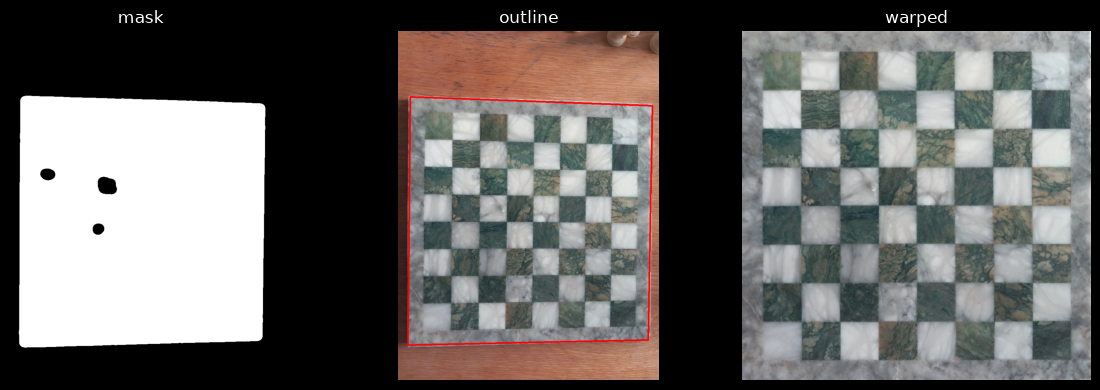

In [28]:
# Run step 1 on the empty board of the selected set and show mask, outline and warped board.
# Mask function per set (key = folder name).
BOARD_MASK = {
    "crystal": saturation_mask,
    "wood-large": canny_mask,
    "wood-small": canny_mask,
}

mask_fn = BOARD_MASK[chess_img.name]
corners = board_corners(empty, mask_fn)
board = warp_board(empty, corners)
show([mask_fn(empty), draw_outline(empty, corners), board], ["mask", "outline", "warped"])

## Step 2: the 64 squares

On the warped board, the mean of the **signed** Sobel gradient along each column (and row) peaks at the square edges: there the gradient has the same sign along the whole line. Texture inside the squares (marble, carvings) has mixed signs and cancels out. A brute-force search then picks 9 equally spaced lines per direction.

`findChessboardCornersSB` is shown as a comparison. It only finds the empty crystal board.

x lines: [32, 88, 145, 202, 258, 315, 372, 428, 485]
y lines: [29, 85, 141, 197, 253, 309, 366, 422, 478]


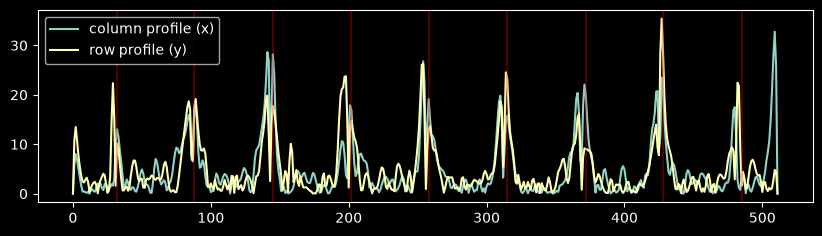

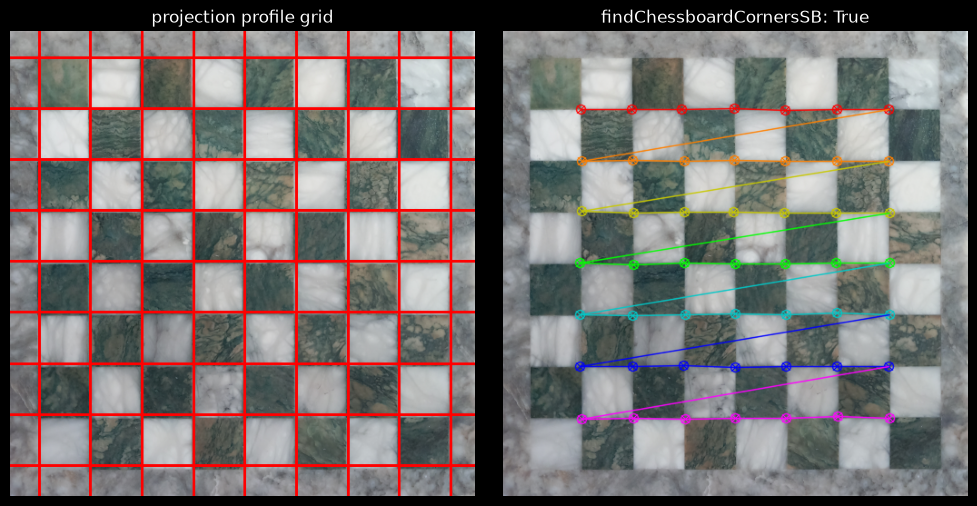

In [29]:
def grid_lines(profile, n_lines=9):
    """Return the positions of n equally spaced lines whose summed profile values are the largest."""
    size = len(profile)
    best_score, best = -1.0, None
    # Try every square width from size/12 (wide border) to size/7.5 (almost no border), in half-pixel steps.
    for step in np.arange(size / 12, size / 7.5, 0.5):
        # Try every start position where all lines still fit inside the image.
        for offset in np.arange(0, size - (n_lines - 1) * step, 1.0):
            idx = (offset + step * np.arange(n_lines)).astype(int)
            # Score = sum of the profile at the line positions; clip guards against indices past the end.
            score = profile[np.clip(idx, 0, size - 1)].sum()
            if score > best_score:
                best_score, best = score, idx
    return best


def find_grid(board):
    """Find the 9 vertical and 9 horizontal grid lines of a warped board from its gradient profiles."""
    gray = cv2.GaussianBlur(cv2.cvtColor(board, cv2.COLOR_BGR2GRAY), (5, 5), 0).astype(np.float32)
    # cv2.Sobel: computes the image gradient (brightness change); dx=1, dy=0 is the change in x direction.
    # Mean of the signed gradient per column (per row for y), then absolute value:
    # lines whose gradient keeps one sign add up, mixed signs from texture cancel out.
    profile_x = np.abs(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3).mean(axis=0))
    profile_y = np.abs(cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3).mean(axis=1))
    return grid_lines(profile_x), grid_lines(profile_y), profile_x, profile_y


def draw_grid(board, xs, ys):
    """Return a copy of the board with the grid lines drawn in red."""
    out = board.copy()
    for x in xs:
        # cv2.line: draws a straight line between two points with the given colour and thickness.
        cv2.line(out, (int(x), 0), (int(x), out.shape[0]), (0, 0, 255), 2)
    for y in ys:
        cv2.line(out, (0, int(y)), (out.shape[1], int(y)), (0, 0, 255), 2)
    return out


# Find the grid on the warped empty board.
xs, ys, profile_x, profile_y = find_grid(board)
print("x lines:", xs.tolist())
print("y lines:", ys.tolist())

# Plot both profiles; the red lines mark the chosen x positions.
plt.figure(figsize=(10, 2.5))
plt.plot(profile_x, label="column profile (x)")
plt.plot(profile_y, label="row profile (y)")
for x in xs:
    plt.axvline(x, color="red", alpha=0.3)
plt.legend()
plt.show()

# Comparison with OpenCV's built-in detector, which looks for the 7x7 inner corners of the board.
# cv2.findChessboardCornersSB: finds the inner corners of a chessboard pattern; EXHAUSTIVE searches longer but finds more.
found, inner = cv2.findChessboardCornersSB(cv2.cvtColor(board, cv2.COLOR_BGR2GRAY), (7, 7), flags=cv2.CALIB_CB_EXHAUSTIVE)
sb = board.copy()
if found:
    # cv2.drawChessboardCorners: draws the found corners and their order onto the image.
    cv2.drawChessboardCorners(sb, (7, 7), inner, found)
show([draw_grid(board, xs, ys), sb], ["projection profile grid", f"findChessboardCornersSB: {found}"], size=5)

## Step 3: align every photo to the empty board

SIFT keypoints, ratio test (0.75) and a RANSAC homography map each photo onto the empty board. The grid from step 2 then applies to every photo. The difference image to the empty board shows the pieces only.

The rotation column shows why the orientation cannot come from the camera frame: the empty crystal board was photographed turned by about 90°, and `wood-small/5` was taken from the other side of the board.

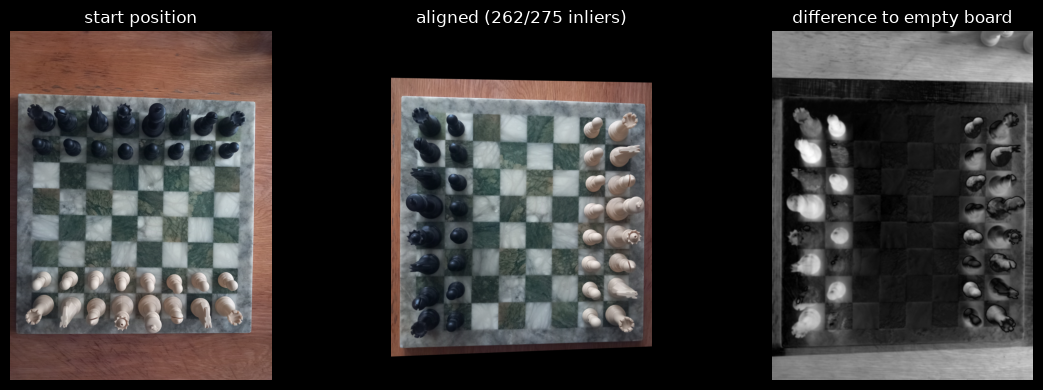

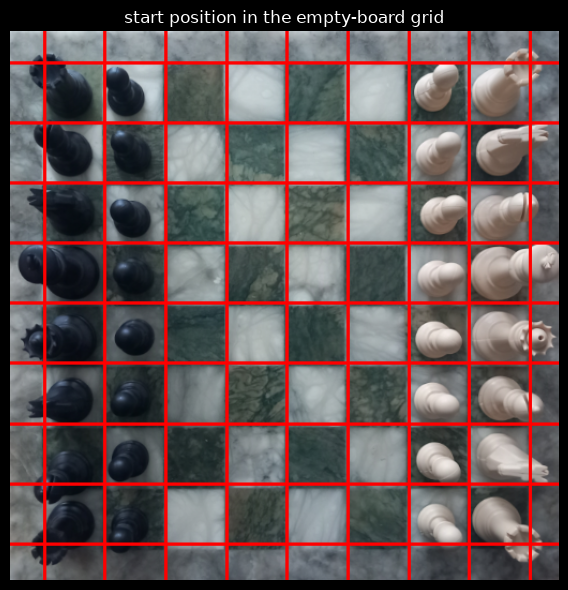

In [30]:
# cv2.SIFT_create: creates a SIFT detector; it finds keypoints and describes each with 128 numbers that survive scaling and rotation.
# 4000 = keep only the 4000 strongest keypoints per image.
sift = cv2.SIFT_create(4000)
# cv2.BFMatcher: brute-force matcher that compares every descriptor of one image with every descriptor of the other.
matcher = cv2.BFMatcher()


def align(reference, img):
    """Return the homography that maps img onto reference, plus the RANSAC inlier and match counts."""
    # detectAndCompute: finds the keypoints and computes their descriptors in one call (None = no mask).
    kp_ref, des_ref = sift.detectAndCompute(cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY), None)
    kp_img, des_img = sift.detectAndCompute(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), None)
    # knnMatch: returns the k best matches per descriptor, here the best and the second best (k=2).
    # Ratio test: keep a match only if it is clearly better than the second best, which drops ambiguous matches.
    good = [m for m, n in matcher.knnMatch(des_img, des_ref, k=2) if m.distance < 0.75 * n.distance]
    # Pixel coordinates of the matched keypoints in both images.
    src = np.float32([kp_img[m.queryIdx].pt for m in good])
    dst = np.float32([kp_ref[m.trainIdx].pt for m in good])
    # cv2.findHomography: estimates a 3x3 homography from point pairs; RANSAC ignores pairs that miss by more than 5 px.
    H, inlier_mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    return H, int(inlier_mask.sum()), len(good)


def difference(a, b):
    """Return the absolute difference of two aligned images as a grayscale image stretched to 0..255."""
    # cv2.absdiff: per-pixel absolute difference |a - b|, without the overflow of plain uint8 subtraction.
    # Blurring first reduces noise from small misalignments.
    diff = cv2.absdiff(cv2.GaussianBlur(a, (7, 7), 0), cv2.GaussianBlur(b, (7, 7), 0))
    # cv2.normalize: rescales values; NORM_MINMAX stretches them to the full 0..255 range for display.
    return cv2.normalize(cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY), None, 0, 255, cv2.NORM_MINMAX)


# Align the start position to the empty board.
H, inliers, matches = align(empty, start)
# Map the start photo into the image coordinates of the empty board.
aligned = cv2.warpPerspective(start, H, (empty.shape[1], empty.shape[0]))
show([start, aligned, difference(empty, aligned)],
     ["start position", f"aligned ({inliers}/{matches} inliers)", "difference to empty board"])
# Corners from step 1 and grid from step 2 now fit the start photo as well.
show([draw_grid(warp_board(aligned, corners), xs, ys)], ["start position in the empty-board grid"], size=6)

In [31]:
# Align every photo of the set to the empty board and print the match quality and rotation.
print(f"{'photo':<20}{'inliers':>9}{'matches':>9}{'rotation':>10}")
for path in paths[1:]:
    H, inliers, matches = align(empty, load(path))
    # Rotation of the photo relative to the empty board, from the homography's linear part.
    rotation = np.degrees(np.arctan2(H[0, 1], H[0, 0]))
    print(f"{path.name:<20}{inliers:>9}{matches:>9}{rotation:>9.0f}°")

photo                 inliers  matches  rotation
1.jpg                     262      275       92°
2.jpg                     290      307       91°
3.jpg                     259      284       91°
4.jpg                     220      237       91°
5.jpg                     205      221       91°
6.jpg                     157      169       91°
7.jpg                     133      146       92°
8.jpg                     170      183       92°
9.jpg                     103      116       91°
10.jpg                     94      110       90°
11.jpg                    114      125       91°
12.jpg                    163      173       91°
13.jpg                    128      143       91°
14.jpg                    136      149       93°


## Steps 1 and 2 on all sets

`wood-small` fails: in `wood-small/0` the board is cut off at the left image edge, so the outline and the grid are skewed. Re-take the empty photo or detect the grid on the start position for this set.

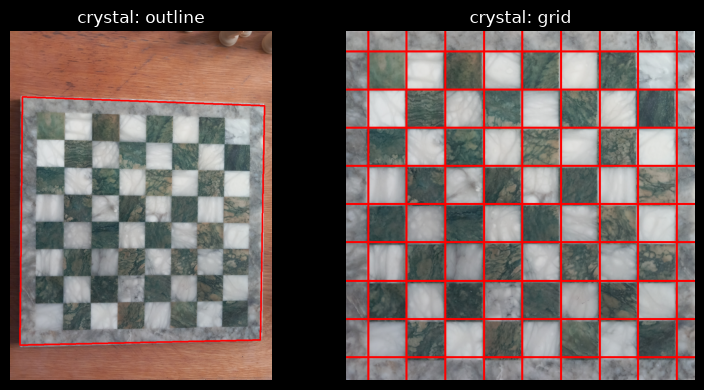

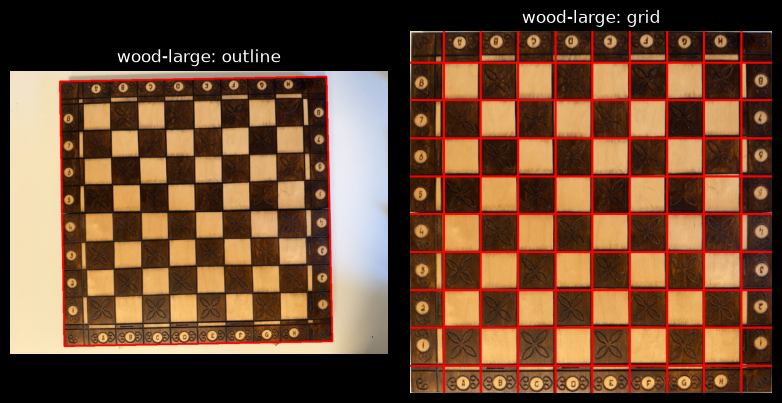

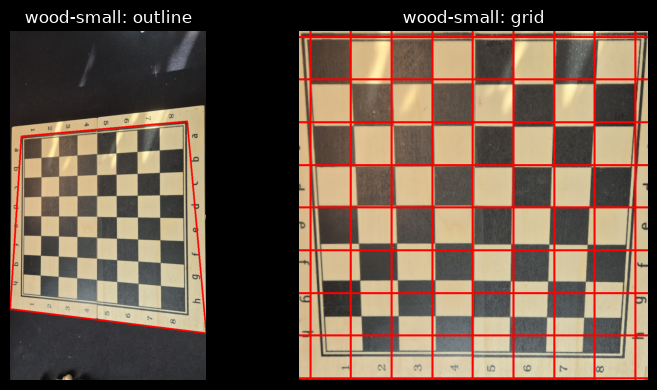

In [32]:
# Run step 1 (outline) and step 2 (grid) on the empty board of every set.
data_root = chess_img.parent
for name, fn in BOARD_MASK.items():
    # Photo 0 of each set is the empty board.
    img = load(photo_paths(data_root / name)[0])
    c = board_corners(img, fn)
    b = warp_board(img, c)
    gx, gy, _, _ = find_grid(b)
    show([draw_outline(img, c), draw_grid(b, gx, gy)], [f"{name}: outline", f"{name}: grid"])